# Operational threshold from a fit of S(φ)

**Internship at CoMuNe Lab** · Riccardo Corte

Neither threshold used so far says when the network stops working in practice: `1/λ_max` marks where a giant component first exists in message passing, even if it holds very few nodes, and the peak of `χ` is a different definition, measured on Monte Carlo. Here the large part of the curve is fitted with a power law and extrapolated to `S = 0`, with the same rule for message passing and Monte Carlo:

`S(φ) = A (φ − φ_fit)^β`

`φ_fit` is an operational threshold and not the critical point: `β` is an effective exponent, not a critical one. The curves are read from the csv of notebooks 04 and 06, no long run here except the check of section 5.

## 0. Setup

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from mp import struttura_mp, curva_mp, struttura_mc, mc_1run_veloce, phi_ibrido, power_law, fit_soglia

cartella_dati = Path("../data/raw/zitnik2019_treeoflife/treeoflife.interactomes")
cartella_ris = Path("risultati/07")
cartella_ris.mkdir(exist_ok=True)

# curves and thresholds of notebooks 04 (test networks) and 06 (proteins)
curve = pd.concat([pd.read_csv("risultati/04/curve_protocolli.csv"),
                   pd.read_csv("risultati/06/curve_protocolli_fpiccole.csv")], ignore_index=True)
soglie_mc = pd.concat([pd.read_csv("risultati/04/soglie_mc.csv"),
                       pd.read_csv("risultati/06/soglie_mc_fpiccole.csv")], ignore_index=True)

reti_test = ["Erdos-Renyi", "Barabasi-Albert", "communities"]
reti_proteine = [r for r in ["Synechocystis", "H. pylori", "P. falciparum", "E. coli"] if r in set(curve["network"])]
print("protein networks in the csv:", reti_proteine)

protein networks in the csv: ['Synechocystis', 'H. pylori', 'P. falciparum', 'E. coli']


## 1. The fit

`fit_soglia` (in `mp.py`) selects the points of one curve with `S` inside the window and fits the power law with `curve_fit`. The window is in values of `S`, not of `φ`, so that it takes the same state of the network on every curve; it is applied separately to each curve, because the same `S` falls at different `φ` in message passing and Monte Carlo. `φ_fit` must stay below the first point used, otherwise `φ − φ_fit` becomes negative. Too few points or no convergence give `nan` and a note, without stopping the loop.

**Windows.** `main`: `0.05 ≤ S ≤ 0.8`. Below 0.05 the curve is dominated by finite-size fluctuations and by the long tail near the threshold: the peak of `χ` falls at `S` about 0.03 to 0.05 on these networks. `low` and `wide` measure how much the result depends on the choice.

In [2]:
finestre = {"main": (0.05, 0.8), "low": (0.1, 0.6), "wide": (0.05, 0.95)}

## 2. Checks with a known answer

**2.1 Artificial curve.** `A`, `φ_fit` and `β` chosen by hand, with and without noise: the fit must give them back.

**2.2 Erdős-Rényi.** The only network where the threshold is known: `1/⟨k⟩ = 1/3` for the large network (`⟨k⟩ = 3`), and `1/λ_max` on this graph. The curve is near the threshold only partly linear, so the comparison says how far `φ_fit` falls from the true threshold when it is known.

In [3]:
# 2.1 artificial curve
rng = np.random.default_rng(0)
phi_prova = np.arange(0.2, 1.0001, 0.01)
righe = []
for rumore in [0.0, 0.002]:
    for vero in [(1.0, 0.15, 1.2), (0.9, 0.05, 1.05), (1.2, 0.25, 1.4)]:
        S_prova = power_law(phi_prova, *vero) + rumore * rng.normal(size=len(phi_prova))
        r = fit_soglia(phi_prova, S_prova, *finestre["main"])
        righe.append({"noise": rumore, "true phi_fit": vero[1], "phi_fit": r["phi_fit"], "true beta": vero[2], "beta": r["beta"]})
display(pd.DataFrame(righe).round(4))

/home/riccorte/TIROCINIO/lavoro/01_tirocinio/codice/mp.py:501: RuntimeWarning: invalid value encountered in power
  return A * (phi - phi_fit) ** beta


,noise,true phi_fit,phi_fit,true beta,beta
0,0.000,0.15,0.1500,1.20,1.2000
1,0.000,0.05,0.0500,1.05,1.0500
2,0.000,0.25,0.2500,1.40,1.4000
3,0.002,0.15,0.1472,1.20,1.2089
4,0.002,0.05,0.0506,1.05,1.0481
5,0.002,0.25,0.2474,1.40,1.4038


In [4]:
# 2.2 Erdos-Renyi, no screening
t = curve[(curve["network"] == "Erdos-Renyi") & (curve["protocol"] == "random") & (curve["f"] == 0)].sort_values("phi")
righe = []
for nome_f, (S_min, S_max) in finestre.items():
    for metodo in ["S MP", "S MC"]:
        r = fit_soglia(t["phi"], t[metodo], S_min, S_max)
        righe.append({"window": nome_f, "method": metodo, "phi_fit": r["phi_fit"], "beta": r["beta"], "rms": r["rms"], "points": r["points"]})
print(f"1/<k> = {1/3:.3f}, 1/lambda_max = {t['phi_c'].iloc[0]:.3f}")
display(pd.DataFrame(righe).round(4))

1/<k> = 0.333, 1/lambda_max = 0.341


,window,method,phi_fit,beta,rms,points
0,main,S MP,0.3496,0.8094,0.0011,18
1,main,S MC,0.3246,0.9395,0.0123,22
2,low,S MP,0.3505,0.8092,0.0005,13
3,low,S MC,0.3487,0.8489,0.0064,13
4,wide,S MP,0.3505,0.8031,0.0013,21
5,wide,S MC,0.3293,0.8943,0.0131,25


#### Comment on section 2

**Artificial curve.** Without noise the fit gives back `A`, `φ_fit` and `β` exactly. With noise 0.002 on `S` the threshold moves by 0.003 at most and `β` by 0.009 at most.

**Erdős-Rényi.** Message passing gives `φ_fit` = 0.350-0.351 in all three windows, within 0.01 of `1/λ_max = 0.341` (and 0.017 above `1/⟨k⟩ = 1/3`). Monte Carlo gives 0.325 in the main window, 0.349 in the low one and 0.329 in the wide one: about 0.02 below message passing, and up to 0.024 apart between the windows. The window matters little for message passing and more for Monte Carlo, whose points are noisier (RMS of the fit 0.012 against 0.001). So the fit gives back a known threshold within 0.01-0.02.

## 3. Fit on the curves

Cases: no screening (`f = 0`) and `f = 0.03` with random, degree and betweenness screening. For each draw of screened nodes one fit, then mean and standard deviation over the draws: the curve averaged over the draws would mix networks with different thresholds. With `f > 0` the curve does not reach zero, since `S(0)` is about `f`: two variants, `S` as it is and `S − f`, which counts roughly the non-screened nodes connected. In the variant `S − f` the window applies to `S − f`.

In [5]:
casi = [("random", 0.0), ("random", 0.03), ("degree", 0.03), ("betweenness", 0.03)]

righe = []
for nome in reti_test + reti_proteine:
    for protocollo, frazione in casi:
        t_caso = curve[(curve["network"] == nome) & (curve["protocol"] == protocollo) & (curve["f"] == frazione)]
        for draw, t in t_caso.groupby("draw"):
            t = t.sort_values("phi")
            for metodo in ["MP", "MC"]:
                for variante in (["S"] if frazione == 0 else ["S", "S - f"]):
                    valori = t[f"S {metodo}"] - (frazione if variante == "S - f" else 0)
                    for nome_f, (S_min, S_max) in finestre.items():
                        r = fit_soglia(t["phi"], valori, S_min, S_max)
                        righe.append({"network": nome, "protocol": protocollo, "f": frazione, "draw": draw,
                                      "method": metodo, "variant": variante, "window": nome_f, **r})
fit = pd.DataFrame(righe)
fit.to_csv(cartella_ris / "fit_soglie.csv", index=False)
print(len(fit), "fits;", (fit["note"] != "").sum(), "not done:")
display(fit[fit["note"] != ""].groupby(["network", "protocol", "f", "method", "variant", "window", "note"]).size())

1566 fits; 0 not done:


Series([], dtype: int64)

### 3.1 Comparison

Main window. `φ_fit` of message passing and Monte Carlo (mean and standard deviation over the draws) and their difference, next to the two thresholds used so far: `1/λ` from the bisection and the peak of `χ`.

In [6]:
chiavi = ["network", "protocol", "f", "variant"]
principale = fit[fit["window"] == "main"]
sintesi = principale.groupby(chiavi + ["method"], sort=False).agg(
    phi_fit=("phi_fit", "mean"), std=("phi_fit", "std"), beta=("beta", "mean"), rms=("rms", "mean"), points=("points", "mean")).unstack("method")
sintesi.columns = [f"{a} {b}" for a, b in sintesi.columns]
sintesi["MC - MP"] = sintesi["phi_fit MC"] - sintesi["phi_fit MP"]

altre = soglie_mc.groupby(["network", "protocol", "f"], sort=False)[["phi_c MP", "phi_c MC"]].mean().reset_index()
altre["f"] = altre["f"].round(3)
altre = altre.rename(columns={"phi_c MP": "1/lambda", "phi_c MC": "chi peak"})
sintesi = sintesi.reset_index().merge(altre, on=["network", "protocol", "f"], how="left")
display(sintesi[chiavi + ["phi_fit MP", "std MP", "phi_fit MC", "std MC", "MC - MP", "beta MP", "beta MC", "rms MP", "rms MC",
                          "points MP", "points MC", "1/lambda", "chi peak"]].round(4))

,network,protocol,f,variant,phi_fit MP,std MP,phi_fit MC,std MC,MC - MP,beta MP,beta MC,rms MP,rms MC,points MP,points MC,1/lambda,chi peak
0,Erdos-Renyi,random,0.00,S,0.3496,NaN,0.3246,NaN,-0.0250,0.8094,0.9395,0.0011,0.0123,18.0000,22.0000,0.3412,0.3912
1,Erdos-Renyi,random,0.03,S,0.3286,0.0052,0.3066,0.0058,-0.0221,0.8126,0.9312,0.0012,0.0132,19.0000,21.7273,0.3214,0.3652
2,Erdos-Renyi,random,0.03,S - f,0.3437,0.0049,0.3409,0.0076,-0.0028,0.8180,0.8516,0.0011,0.0104,17.7273,18.4545,0.3214,0.3652
3,Erdos-Renyi,degree,0.03,S,0.2386,0.0063,0.2235,0.0106,-0.0151,0.9263,1.0009,0.0005,0.0096,19.7273,22.0000,0.2432,0.2931
4,Erdos-Renyi,degree,0.03,S - f,0.2590,0.0053,0.2623,0.0075,0.0033,0.9323,0.9346,0.0006,0.0071,18.7273,18.5455,0.2432,0.2931
5,Erdos-Renyi,betweenness,0.03,S,0.1816,NaN,0.1722,NaN,-0.0095,1.0689,1.1233,0.0024,0.0062,20.0000,22.0000,0.2036,0.2486
6,Erdos-Renyi,betweenness,0.03,S - f,0.2131,NaN,0.2245,NaN,0.0114,1.0493,1.0326,0.0030,0.0042,18.0000,17.0000,0.2036,0.2486
7,Barabasi-Albert,random,0.00,S,0.1349,NaN,0.1427,NaN,0.0078,0.9473,0.9307,0.0046,0.0044,16.0000,15.0000,0.0930,0.1450
8,Barabasi-Albert,random,0.03,S,0.1076,0.0119,0.1113,0.0131,0.0037,0.9586,0.9494,0.0040,0.0067,17.5455,17.7273,0.0710,0.1436
9,Barabasi-Albert,random,0.03,S - f,0.1399,0.0088,0.1441,0.0112,0.0041,0.9252,0.9145,0.0037,0.0056,15.4545,15.0000,0.0710,0.1436


### 3.2 Sensitivity to the window

`φ_fit` in each window (mean over the draws) and the spread across the windows, to be compared with the difference between the two methods.

In [7]:
sens = fit.groupby(chiavi + ["method", "window"], sort=False)["phi_fit"].mean().unstack("window")[list(finestre)]
sens["spread"] = sens.max(axis=1) - sens.min(axis=1)
display(sens.round(4))

window                                         main     low    wide  spread
network     protocol    f    variant method                                
Erdos-Renyi random      0.00 S       MP      0.3496  0.3505  0.3505  0.0008
                                     MC      0.3246  0.3487  0.3293  0.0241
                        0.03 S       MP      0.3286  0.3305  0.3295  0.0019
                                     MC      0.3066  0.3365  0.3120  0.0299
                             S - f   MP      0.3437  0.3446  0.3443  0.0009
...                                             ...     ...     ...     ...
E. coli     degree      0.03 S - f   MC      0.0141  0.0175  0.0180  0.0039
            betweenness 0.03 S       MP     -0.0478 -0.0415 -0.0429  0.0063
                                     MC     -0.0512 -0.0474 -0.0461  0.0050
                             S - f   MP      0.0042  0.0048  0.0066  0.0024
                                     MC      0.0014  0.0026  0.0041  0.0027

[98 rows x 4 columns]

### 3.3 Fits on the curves, with the residuals

Main window. Dots: `S`, one draw (the first) for each case. Line: the fit, drawn only over the points used. Below each panel the residuals `S − fit`: a fit with a low RMS can still be systematically wrong, and that shows here as a pattern and not as scatter around zero.

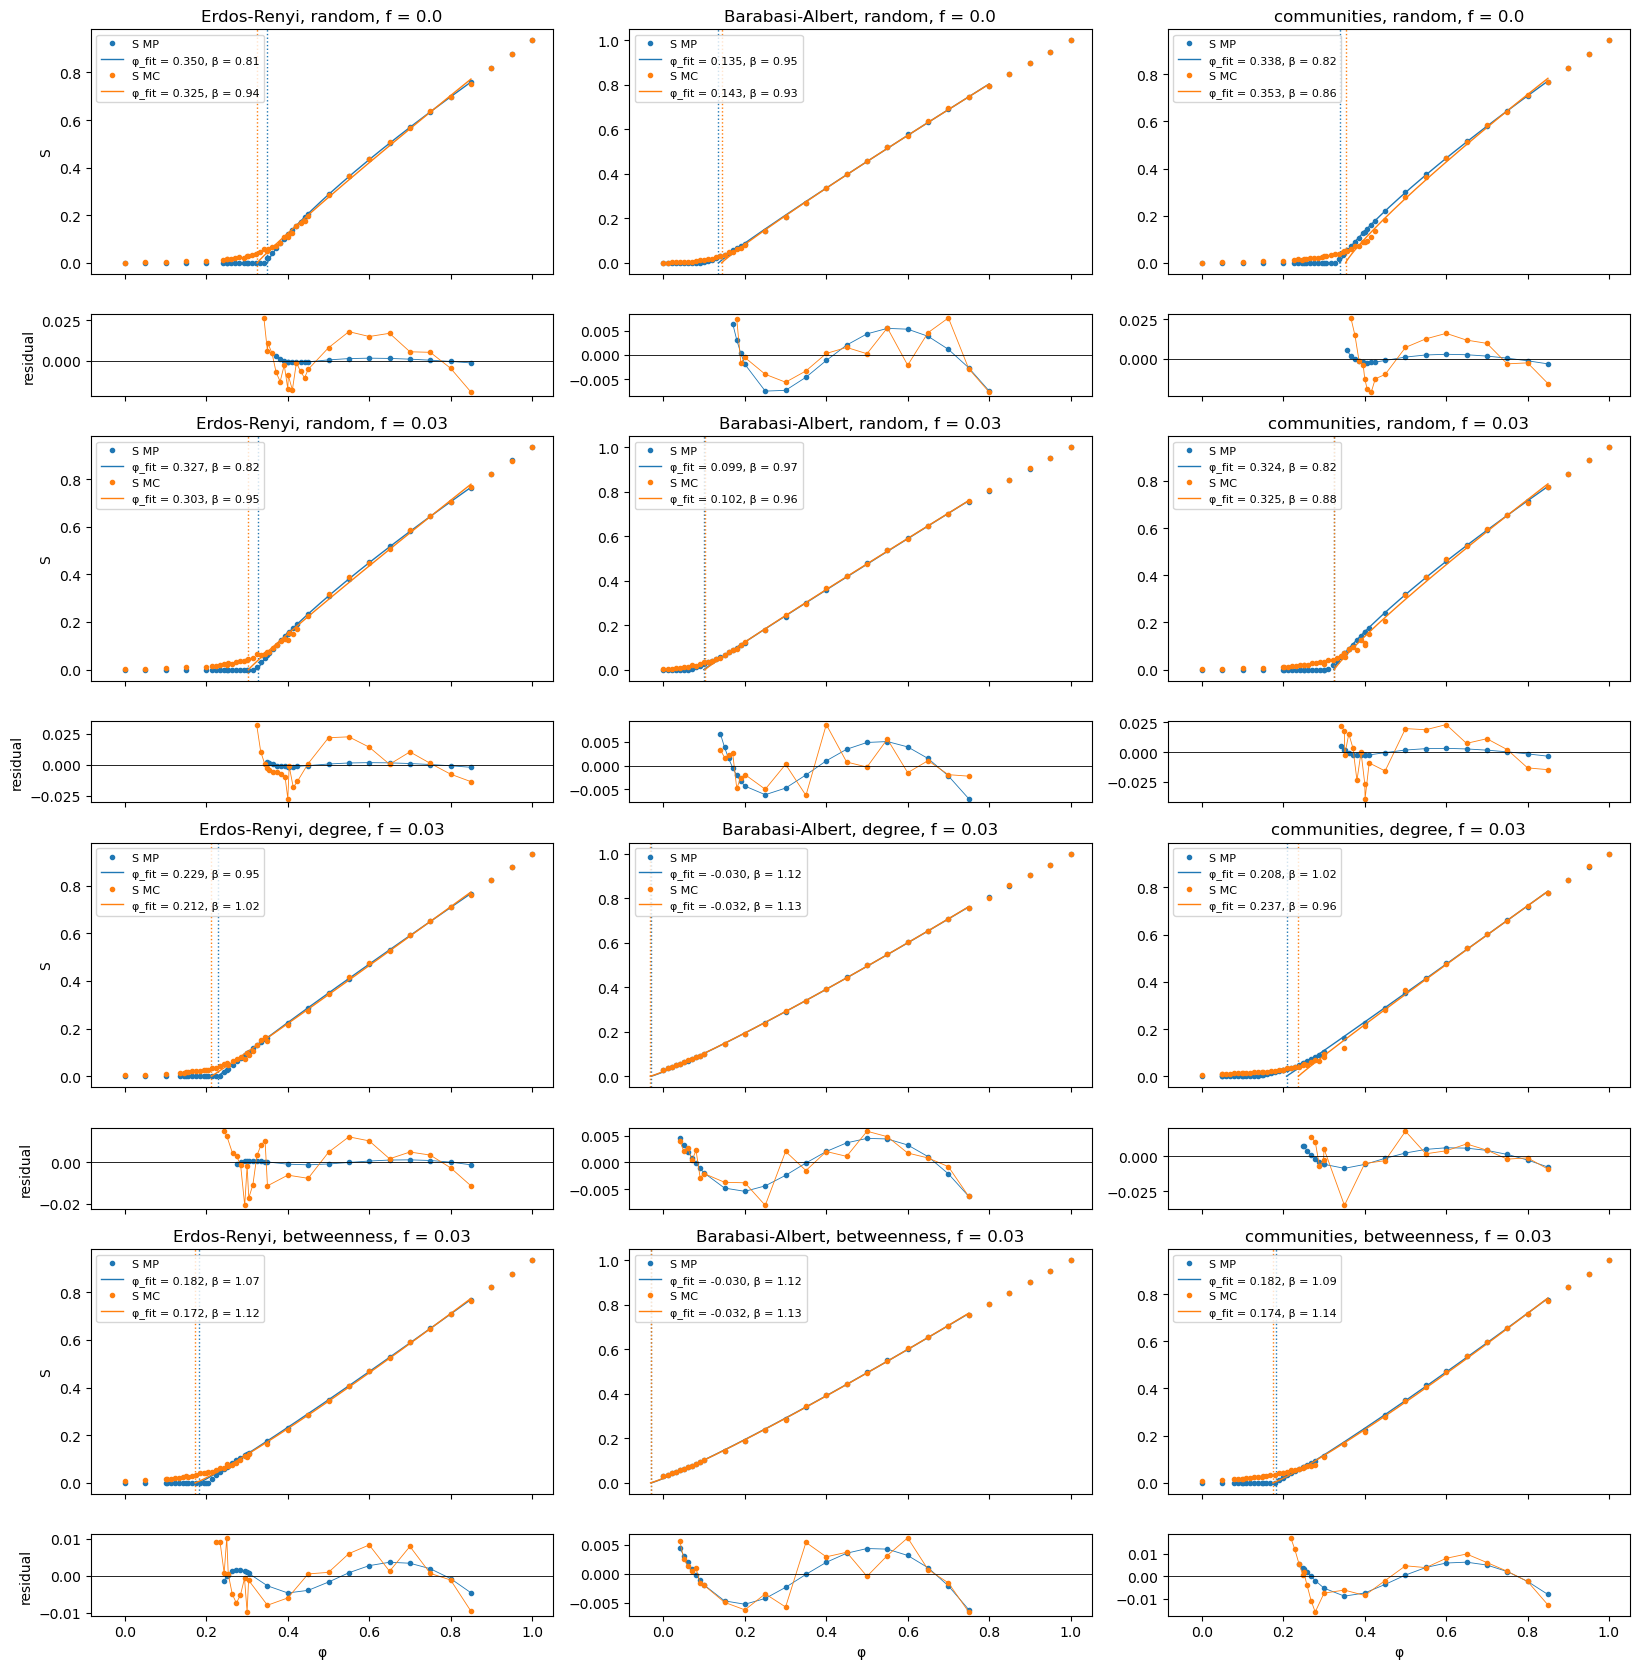

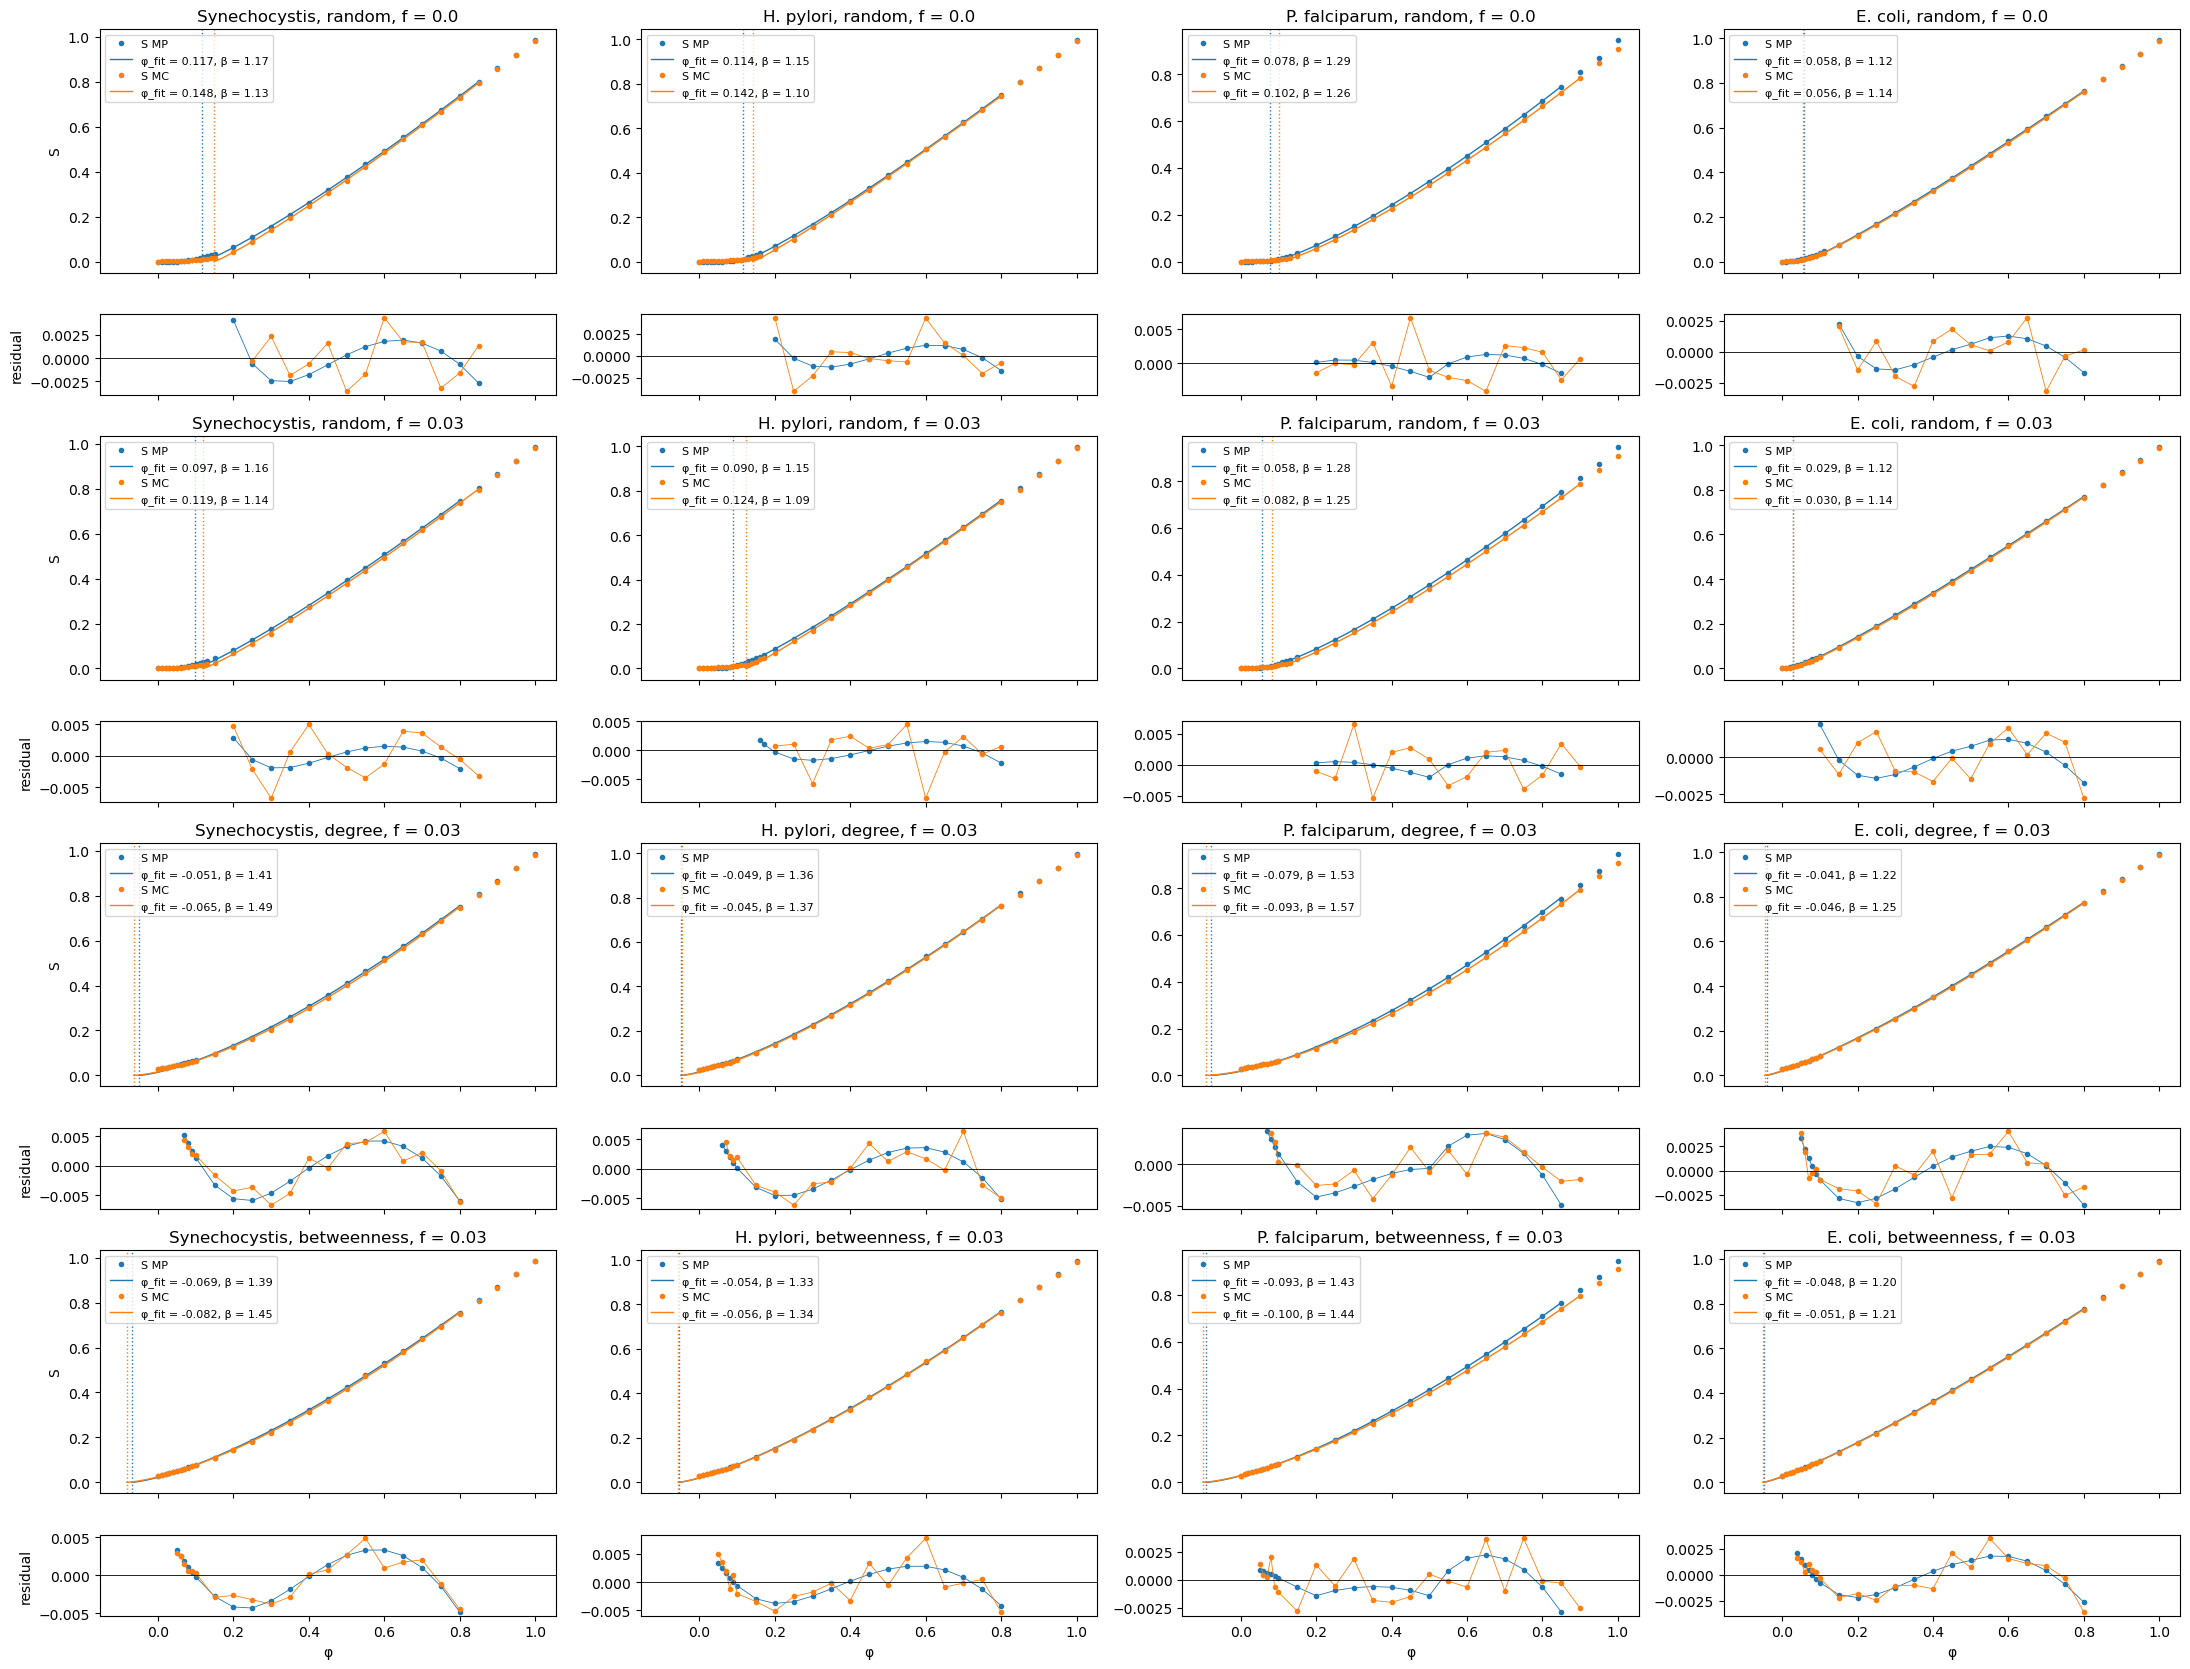

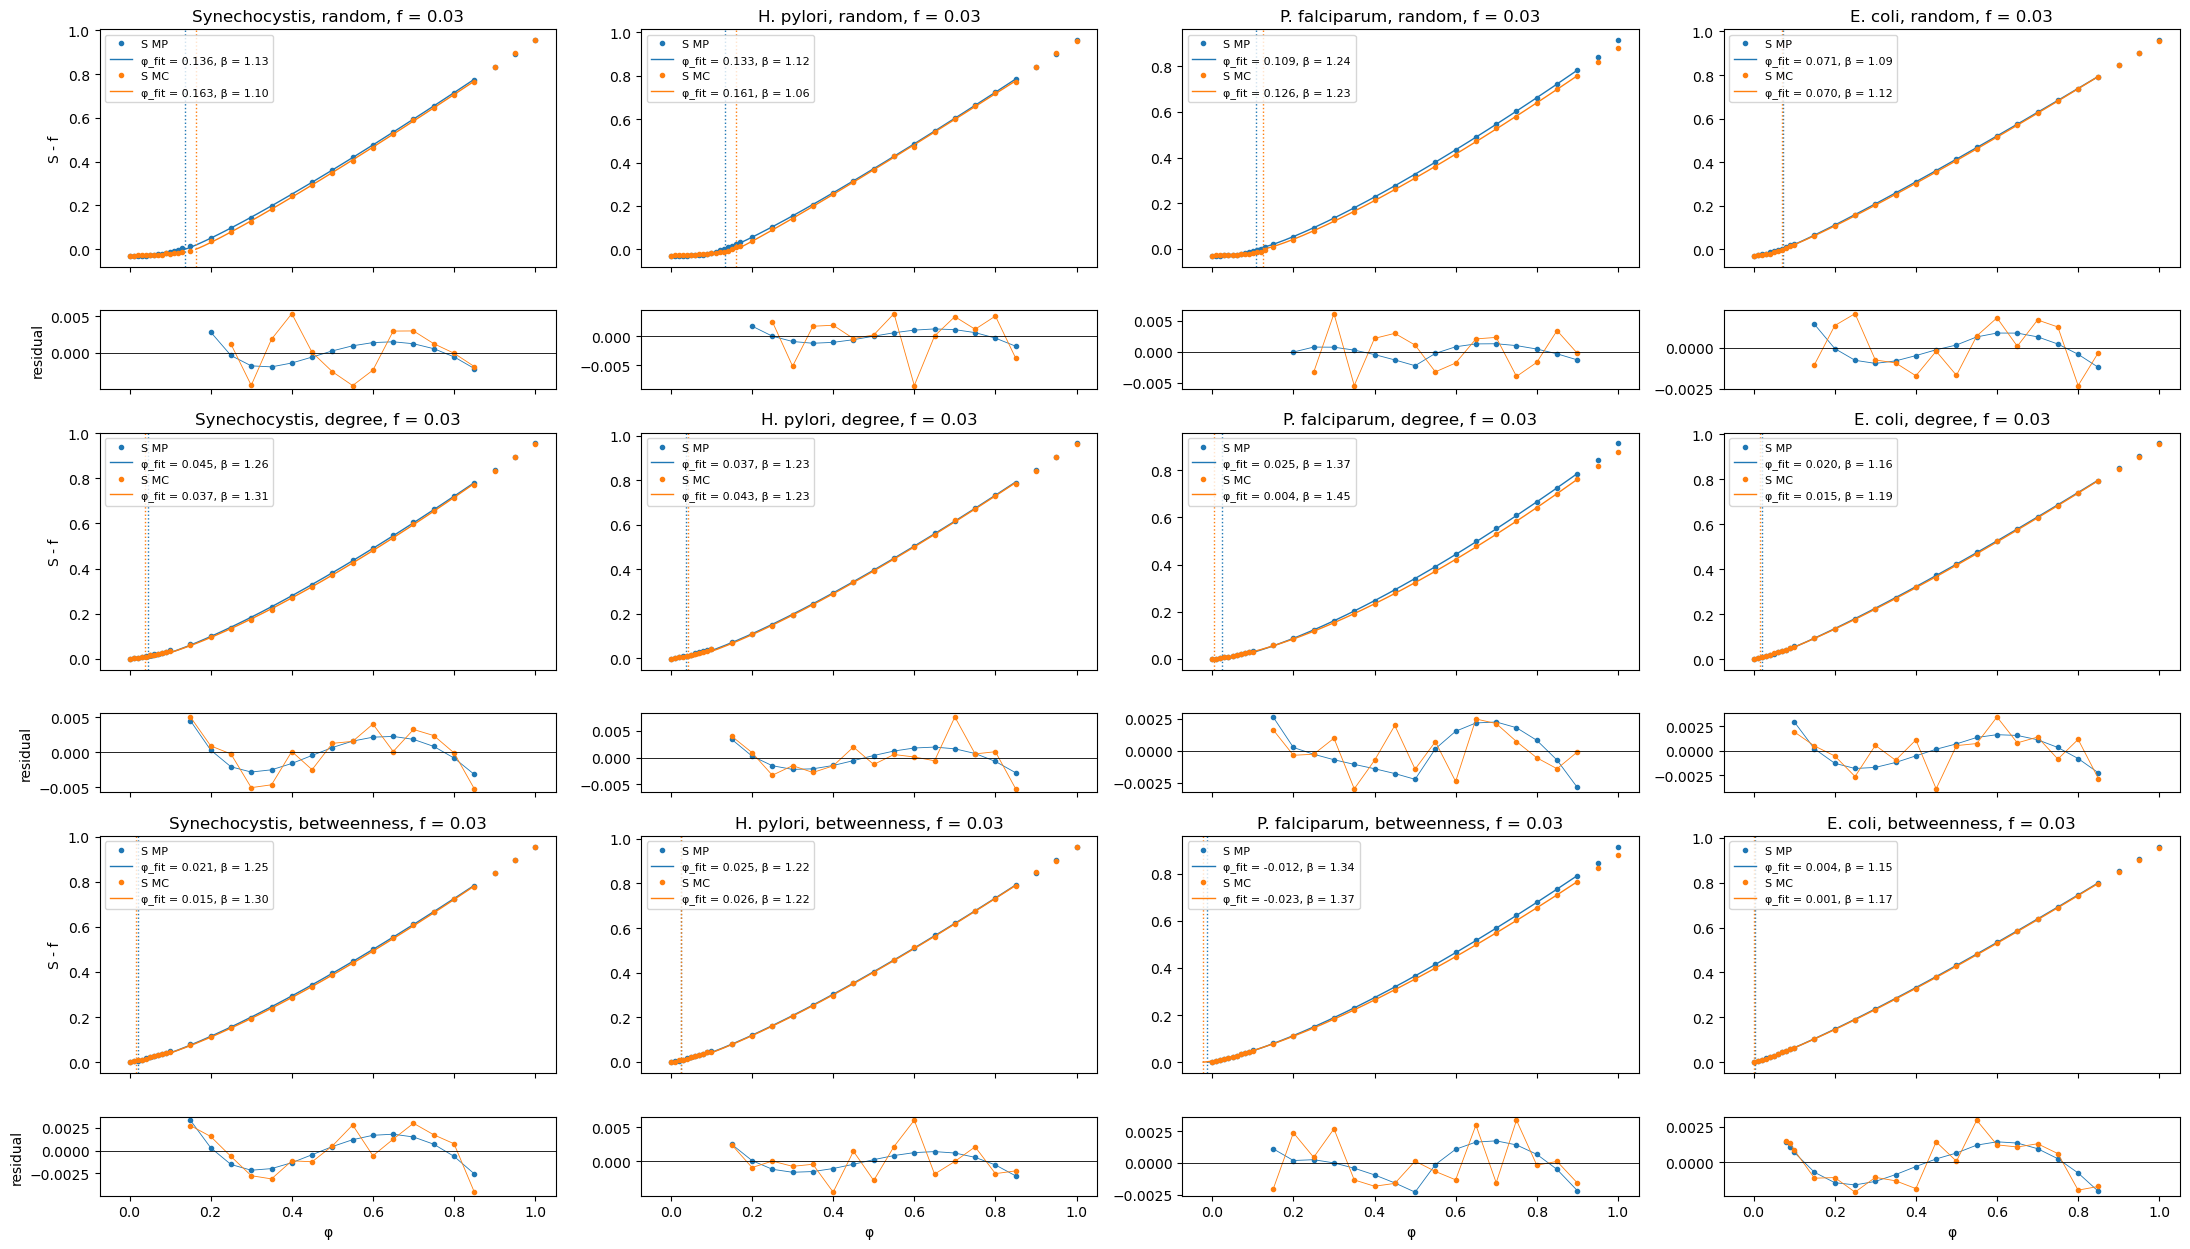

In [8]:
def disegna_fit(reti, variante="S"):
    """One column per network, one pair of panels (curve and residuals) per case."""
    casi_var = [c for c in casi if variante == "S" or c[1] > 0]
    fig, assi = plt.subplots(2 * len(casi_var), len(reti), figsize=(5.5 * len(reti), 4.2 * len(casi_var)), sharex=True,
                             squeeze=False, gridspec_kw={"height_ratios": [3, 1] * len(casi_var)})
    S_min, S_max = finestre["main"]
    for r, (protocollo, frazione) in enumerate(casi_var):
        for col, nome in enumerate(reti):
            ax, ax_res = assi[2 * r, col], assi[2 * r + 1, col]
            t = curve[(curve["network"] == nome) & (curve["protocol"] == protocollo) & (curve["f"] == frazione)]
            t = t[t["draw"] == t["draw"].min()].sort_values("phi")
            for metodo, colore in [("MP", "tab:blue"), ("MC", "tab:orange")]:
                x = t["phi"].values
                y = t[f"S {metodo}"].values - (frazione if variante == "S - f" else 0)
                ris = fit_soglia(x, y, S_min, S_max)
                ax.plot(x, y, "o", color=colore, ms=3, label=f"S {metodo}")
                if np.isnan(ris["phi_fit"]):
                    continue
                dentro = (y >= S_min) & (y <= S_max)
                x_fit = np.linspace(ris["phi_fit"] + 1e-6, x[dentro].max(), 200)
                ax.plot(x_fit, power_law(x_fit, ris["A"], ris["phi_fit"], ris["beta"]), "-", color=colore, lw=1,
                        label=f"φ_fit = {ris['phi_fit']:.3f}, β = {ris['beta']:.2f}")
                ax.axvline(ris["phi_fit"], color=colore, ls=":", lw=1)
                ax_res.plot(x[dentro], y[dentro] - power_law(x[dentro], ris["A"], ris["phi_fit"], ris["beta"]),
                            "o-", color=colore, ms=3, lw=0.6)
            ax.set_title(f"{nome}, {protocollo}, f = {frazione}")
            ax.legend(fontsize=8, loc="upper left")
            ax_res.axhline(0, color="k", lw=0.6)
        assi[2 * r, 0].set_ylabel(variante)
        assi[2 * r + 1, 0].set_ylabel("residual")
    for ax in assi[-1]:
        ax.set_xlabel("φ")
    plt.tight_layout()
    plt.show()


disegna_fit(reti_test)
disegna_fit(reti_proteine)
disegna_fit(reti_proteine, variante="S - f")

#### Comment on section 3

**No screening.** On the test networks `φ_fit` of the two methods differs by 0.008 to 0.025 (Erdős-Rényi: Monte Carlo 0.025 below message passing; Barabási-Albert and communities: 0.008 and 0.015 above). On the proteins Monte Carlo is 0.024 to 0.031 above message passing (Synechocystis, H. pylori, P. falciparum) and the two coincide on E. coli (−0.002), against 0.07 to 0.16 between `1/λ` and the peak of `χ`: most of the gap between the thresholds used so far came from their two different definitions. What is left has the sign expected from short cycles (notebook 02): message passing slightly below Monte Carlo.

**With screening, f = 0.03.** With random screening the picture is the same as without. With degree and betweenness the variant `S` gives a negative `φ_fit` on Barabási-Albert and on all the proteins (−0.03 to −0.10): the screened nodes alone already form a giant component (`1/λ = 0` in the table, `S(0) ≈ f`), so the curve does not go to zero and the extrapolation falls below `φ = 0`, where it has no meaning. In the variant `S − f`, which counts roughly the non-screened nodes connected, `φ_fit` is between −0.02 and 0.05 and the two methods differ by 0.02 at most. In these cases the fit only says that the network has no threshold.

**Windows (section 3.2).** The spread across the three windows has median 0.007 for message passing and 0.010 for Monte Carlo, up to 0.03-0.05 in a few cases (Monte Carlo on communities and Erdős-Rényi, and the negative `φ_fit` with degree screening). On the proteins without screening it stays below the gap between the two methods.

**Fits (section 3.3).** The RMS of the fit is 0.0003-0.006 for message passing and 0.001-0.020 for Monte Carlo. The residuals show a systematic wave on some curves: the power law is only an approximation of the shape of `S(φ)`, so `φ_fit` is an operational threshold, not the critical point.

## 4. Why message passing stays above Monte Carlo at large `S` on some networks

On P. falciparum the difference does not shrink with `S`. Hypothesis to check: `S` message passing also counts the components with a cycle other than the largest one (notebook 05, section 3), while Monte Carlo measures only the largest. At `φ = 1` the two quantities can be computed directly: the largest component as a fraction of `N`, and the sum of the components containing a cycle.

In [9]:
specie = {1148: "Synechocystis", 85962: "H. pylori", 5833: "P. falciparum", 511145: "E. coli"}
reti_g = {nome: nx.read_edgelist(cartella_dati / f"{sid}.txt") for sid, nome in specie.items()}

righe = []
for nome, g in reti_g.items():
    componenti = [g.subgraph(c) for c in nx.connected_components(g)]
    con_ciclo = [c for c in componenti if c.number_of_edges() >= c.number_of_nodes()]
    N = g.number_of_nodes()
    S_mp_1 = curva_mp(g, [1.0], (), struttura_mp(g))[0]
    righe.append({"network": nome, "N": N, "components": len(componenti), "components with a cycle": len(con_ciclo),
                  "LCC / N": max(c.number_of_nodes() for c in componenti) / N,
                  "with a cycle / N": sum(c.number_of_nodes() for c in con_ciclo) / N, "S MP at phi = 1": S_mp_1})
display(pd.DataFrame(righe).round(4))

,network,N,components,components with a cycle,LCC / N,with a cycle / N,S MP at phi = 1
0,Synechocystis,2185,18,2,0.9835,0.9849,0.9849
1,H. pylori,1138,5,2,0.9921,0.9947,0.9947
2,P. falciparum,1688,56,13,0.9088,0.9443,0.9443
3,E. coli,3068,19,4,0.9866,0.9902,0.9902


#### Comment on section 4

On every protein network `S` message passing at `φ = 1` equals the fraction of nodes in components with a cycle (0.985, 0.995, 0.944, 0.990), not the largest component (0.984, 0.992, 0.909, 0.987). The difference is small where one component holds almost all the nodes, and 0.035 on P. falciparum, which has 56 components, 13 of them with a cycle. This confirms the hypothesis: at large `S` message passing stays above Monte Carlo on P. falciparum because it also counts the smaller components with a cycle (notebook 05, section 3), which Monte Carlo leaves out. It is a difference of definition, not an error of message passing, and it is also why P. falciparum has the largest RMS deviation in notebook 06, section 5.

## 5. Does the grid matter? Check on one case

The csv have about 13 to 19 points in the main window, with step 0.05 in the upper part, and 20 to 50 Monte Carlo runs. Here one case (Synechocystis, `f = 0`) on a grid with step 0.01 and 200 runs, repeated 5 times with independent Monte Carlo runs: the spread over the repetitions is the real noise of `φ_fit`, to be compared with the difference from the csv. New curves are computed only if the threshold moves by more than this noise. About 4 minutes.

In [10]:
nome_griglia = "Synechocystis"
g = reti_g[nome_griglia]
phi_fitta = np.round(np.arange(0.05, 1.0001, 0.01), 3)
struttura = struttura_mc(g)
S_mp_fitta = curva_mp(g, phi_fitta, (), struttura_mp(g))
rng_5 = np.random.default_rng(5)

fitte = []
for ripetizione in range(5):
    S_mc_fitta = np.array([np.mean([mc_1run_veloce(g, phi_ibrido(g, (), p), rng_5, struttura) for _ in range(200)])
                           for p in phi_fitta])
    for nome_f, (S_min, S_max) in finestre.items():
        r = fit_soglia(phi_fitta, S_mc_fitta, S_min, S_max)
        fitte.append({"window": nome_f, "repetition": ripetizione, "phi_fit": r["phi_fit"], "beta": r["beta"]})
fitte = pd.DataFrame(fitte)

dal_csv = fit[(fit["network"] == nome_griglia) & (fit["f"] == 0)].set_index(["method", "window"])["phi_fit"]
righe = []
for nome_f, (S_min, S_max) in finestre.items():
    q = fitte[fitte["window"] == nome_f]["phi_fit"]
    righe.append({"window": nome_f,
                  "MP csv": dal_csv["MP", nome_f], "MP fine grid": fit_soglia(phi_fitta, S_mp_fitta, S_min, S_max)["phi_fit"],
                  "MC csv": dal_csv["MC", nome_f], "MC fine grid": q.mean(), "MC std of the repetitions": q.std()})
display(pd.DataFrame(righe).round(4))

,window,MP csv,MP fine grid,MC csv,MC fine grid,MC std of the repetitions
0,main,0.1170,0.1155,0.1484,0.1442,0.0008
1,low,0.1157,0.1191,0.1303,0.1404,0.0018
2,wide,0.1218,0.1213,0.1513,0.1483,0.0007


#### Comment on section 5

On the fine grid message passing moves by 0.001 to 0.003. Monte Carlo moves more: 0.148 → 0.144 in the main window, 0.130 → 0.140 in the low one and 0.151 → 0.148 in the wide one, while the standard deviation over the 5 repetitions is 0.001-0.002. The shift (0.003 to 0.010) is larger than the noise, so by the criterion of this section the curves of the csv should be computed again on a finer grid. The shift is still small compared with the gap between the thresholds used before (0.16 on Synechocystis) and with the gap between the two methods with the fit (0.031): the conclusions of section 3 do not change, but the Monte Carlo `φ_fit` is known only to about ±0.01. Not done yet: new curves on the finer grid.

## Conclusions

- The power-law fit gives one operational threshold with the same rule for message passing and Monte Carlo, and gives back known thresholds within 0.01-0.02 (section 2).
- With this common definition the gap between the two methods on the protein networks drops from 0.07-0.16 (`1/λ` against the peak of `χ`) to 0.03 at most: most of the earlier gap came from the definition of the threshold, not from message passing. The gap that is left has the sign expected from short cycles (section 3).
- At large `S` message passing stays above Monte Carlo where the network has several components with a cycle (P. falciparum): a difference of definition (section 4).
- Limits: the power law is only approximate (residuals with a pattern); with targeted screening that removes the threshold the fit has no meaning (negative `φ_fit`); the grid of the Monte Carlo curves moves `φ_fit` by up to 0.01 (section 5).